# Data Cleaning - Quantium Chips

## 1. Imports

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

## 2. Data Loading

In [2]:
transaction = pd.read_excel('data/QVI_transaction_data.xlsx')
pur_behavior = pd.read_csv('data/QVI_purchase_behaviour.csv')

## 3. Exploration - transaction table

In [3]:
transaction.head()

,DATE,STORE_NBR,LYLTY_CARD_NBR,TXN_ID,PROD_NBR,PROD_NAME,PROD_QTY,TOT_SALES
0,43390,1,1000,1,5,Natural Chip Compny SeaSalt175g,2,6.0
1,43599,1,1307,348,66,CCs Nacho Cheese 175g,3,6.3
2,43605,1,1343,383,61,Smiths Crinkle Cut Chips Chicken 170g,2,2.9
3,43329,2,2373,974,69,Smiths Chip Thinly S/Cream&Onion 175g,5,15.0
4,43330,2,2426,1038,108,Kettle Tortilla ChpsHny&Jlpno Chili 150g,3,13.8


In [4]:
transaction.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 264836 entries, 0 to 264835
Data columns (total 8 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   DATE            264836 non-null  int64  
 1   STORE_NBR       264836 non-null  int64  
 2   LYLTY_CARD_NBR  264836 non-null  int64  
 3   TXN_ID          264836 non-null  int64  
 4   PROD_NBR        264836 non-null  int64  
 5   PROD_NAME       264836 non-null  object 
 6   PROD_QTY        264836 non-null  int64  
 7   TOT_SALES       264836 non-null  float64
dtypes: float64(1), int64(6), object(1)
memory usage: 16.2+ MB


.describe() for numeric values: STORE_NBR, PROD_NBR, PROD_QTY, TOT_SALES

In [5]:
transaction['TOT_SALES'].describe()

count    264836.000000
mean          7.304200
std           3.083226
min           1.500000
25%           5.400000
50%           7.400000
75%           9.200000
max         650.000000
Name: TOT_SALES, dtype: float64

.unique() for text values

In [6]:
transaction['PROD_NAME'].unique()

array(['Natural Chip        Compny SeaSalt175g',
       'CCs Nacho Cheese    175g',
       'Smiths Crinkle Cut  Chips Chicken 170g',
       'Smiths Chip Thinly  S/Cream&Onion 175g',
       'Kettle Tortilla ChpsHny&Jlpno Chili 150g',
       'Old El Paso Salsa   Dip Tomato Mild 300g',
       'Smiths Crinkle Chips Salt & Vinegar 330g',
       'Grain Waves         Sweet Chilli 210g',
       'Doritos Corn Chip Mexican Jalapeno 150g',
       'Grain Waves Sour    Cream&Chives 210G',
       'Kettle Sensations   Siracha Lime 150g',
       'Twisties Cheese     270g', 'WW Crinkle Cut      Chicken 175g',
       'Thins Chips Light&  Tangy 175g', 'CCs Original 175g',
       'Burger Rings 220g', 'NCC Sour Cream &    Garden Chives 175g',
       'Doritos Corn Chip Southern Chicken 150g',
       'Cheezels Cheese Box 125g', 'Smiths Crinkle      Original 330g',
       'Infzns Crn Crnchers Tangy Gcamole 110g',
       'Kettle Sea Salt     And Vinegar 175g',
       'Smiths Chip Thinly  Cut Original 175g', 'K

Checking PROD_NAME sorted (extra spaces, characters, non-chips products)

In [7]:
sorted(transaction['PROD_NAME'].unique())

['Burger Rings 220g',
 'CCs Nacho Cheese    175g',
 'CCs Original 175g',
 'CCs Tasty Cheese    175g',
 'Cheetos Chs & Bacon Balls 190g',
 'Cheetos Puffs 165g',
 'Cheezels Cheese 330g',
 'Cheezels Cheese Box 125g',
 'Cobs Popd Sea Salt  Chips 110g',
 'Cobs Popd Sour Crm  &Chives Chips 110g',
 'Cobs Popd Swt/Chlli &Sr/Cream Chips 110g',
 'Dorito Corn Chp     Supreme 380g',
 'Doritos Cheese      Supreme 330g',
 'Doritos Corn Chip Mexican Jalapeno 150g',
 'Doritos Corn Chip Southern Chicken 150g',
 'Doritos Corn Chips  Cheese Supreme 170g',
 'Doritos Corn Chips  Nacho Cheese 170g',
 'Doritos Corn Chips  Original 170g',
 'Doritos Mexicana    170g',
 'Doritos Salsa       Medium 300g',
 'Doritos Salsa Mild  300g',
 'French Fries Potato Chips 175g',
 'Grain Waves         Sweet Chilli 210g',
 'Grain Waves Sour    Cream&Chives 210G',
 'GrnWves Plus Btroot & Chilli Jam 180g',
 'Infuzions BBQ Rib   Prawn Crackers 110g',
 'Infuzions Mango     Chutny Papadums 70g',
 'Infuzions SourCream&Herbs Veg St

## 4. Cleaning - transaction table

In [8]:
transaction['DATE'] = pd.to_datetime(transaction['DATE'], origin='1899-12-30', unit='D')

In [9]:
transaction['PACK_SIZE'] = transaction['PROD_NAME'].str.extract(r'(\d{2,3})[gG]').astype(int)

In [10]:
transaction['BRAND_NAME'] = transaction['PROD_NAME'].str.split().str[0]
transaction['BRAND_NAME'] = transaction['BRAND_NAME'].replace({'Smith':'Smiths', 'WW':'Woolworths','NCC':'Natural', 'Dorito':'Doritos', 'GrnWves':'Grain', 'Infzns':'Infuzions','RRD':'Red','Snbts':'Sunbites'})
transaction['BRAND_NAME'].unique()

array(['Natural', 'CCs', 'Smiths', 'Kettle', 'Old', 'Grain', 'Doritos',
       'Twisties', 'Woolworths', 'Thins', 'Burger', 'Cheezels',
       'Infuzions', 'Red', 'Pringles', 'Tyrrells', 'Cobs', 'French',
       'Tostitos', 'Cheetos', 'Sunbites'], dtype=object)

In [11]:
transaction[['PROD_NBR', 'PROD_NAME']].drop_duplicates()
transaction[transaction['PROD_NAME'].str.contains('Dip|Salsa')][['PROD_NBR', 'PROD_NAME']].drop_duplicates()

,PROD_NBR,PROD_NAME
5,57,Old El Paso Salsa Dip Tomato Mild 300g
32,64,Red Rock Deli SR Salsa & Mzzrlla 150g
39,107,Smiths Crinkle Cut French OnionDip 150g
44,39,Smiths Crinkle Cut Tomato Salsa 150g
63,101,Doritos Salsa Medium 300g
71,65,Old El Paso Salsa Dip Chnky Tom Ht300g
74,35,Woolworths Mild Salsa 300g
87,59,Old El Paso Salsa Dip Tomato Med 300g
158,76,Woolworths Medium Salsa 300g
689,41,Doritos Salsa Mild 300g


In [12]:
dips_salsa = [57,107,101,65,35,59,76,41]

In [13]:
transaction = transaction[~transaction['PROD_NBR'].isin(dips_salsa)]

In [14]:
transaction['PROD_NAME'].unique()

array(['Natural Chip        Compny SeaSalt175g',
       'CCs Nacho Cheese    175g',
       'Smiths Crinkle Cut  Chips Chicken 170g',
       'Smiths Chip Thinly  S/Cream&Onion 175g',
       'Kettle Tortilla ChpsHny&Jlpno Chili 150g',
       'Smiths Crinkle Chips Salt & Vinegar 330g',
       'Grain Waves         Sweet Chilli 210g',
       'Doritos Corn Chip Mexican Jalapeno 150g',
       'Grain Waves Sour    Cream&Chives 210G',
       'Kettle Sensations   Siracha Lime 150g',
       'Twisties Cheese     270g', 'WW Crinkle Cut      Chicken 175g',
       'Thins Chips Light&  Tangy 175g', 'CCs Original 175g',
       'Burger Rings 220g', 'NCC Sour Cream &    Garden Chives 175g',
       'Doritos Corn Chip Southern Chicken 150g',
       'Cheezels Cheese Box 125g', 'Smiths Crinkle      Original 330g',
       'Infzns Crn Crnchers Tangy Gcamole 110g',
       'Kettle Sea Salt     And Vinegar 175g',
       'Smiths Chip Thinly  Cut Original 175g', 'Kettle Original 175g',
       'Red Rock Deli Thai  C

Checking for duplicates

In [15]:
transaction.duplicated().sum()

np.int64(1)

In [16]:
transaction[transaction.duplicated(keep=False)]

,DATE,STORE_NBR,LYLTY_CARD_NBR,TXN_ID,PROD_NBR,PROD_NAME,PROD_QTY,TOT_SALES,PACK_SIZE,BRAND_NAME
124843,2018-10-01,107,107024,108462,45,Smiths Thinly Cut Roast Chicken 175g,2,6.0,175,Smiths
124845,2018-10-01,107,107024,108462,45,Smiths Thinly Cut Roast Chicken 175g,2,6.0,175,Smiths


In [17]:
transaction = transaction.drop_duplicates()

## 5. Exploration - pur_behavior table

In [18]:
pur_behavior.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 72637 entries, 0 to 72636
Data columns (total 3 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   LYLTY_CARD_NBR    72637 non-null  int64 
 1   LIFESTAGE         72637 non-null  object
 2   PREMIUM_CUSTOMER  72637 non-null  object
dtypes: int64(1), object(2)
memory usage: 1.7+ MB


In [19]:
pur_behavior['LIFESTAGE'].unique()

array(['YOUNG SINGLES/COUPLES', 'YOUNG FAMILIES', 'OLDER SINGLES/COUPLES',
       'MIDAGE SINGLES/COUPLES', 'NEW FAMILIES', 'OLDER FAMILIES',
       'RETIREES'], dtype=object)

In [20]:
pur_behavior['PREMIUM_CUSTOMER'].unique()

array(['Premium', 'Mainstream', 'Budget'], dtype=object)

In [21]:
pur_behavior['LYLTY_CARD_NBR'].duplicated().sum()

np.int64(0)

## 6. Merging the tables

In [22]:
merged = pd.merge(transaction, pur_behavior, on='LYLTY_CARD_NBR', how='left')

In [23]:
merged.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 248231 entries, 0 to 248230
Data columns (total 12 columns):
 #   Column            Non-Null Count   Dtype         
---  ------            --------------   -----         
 0   DATE              248231 non-null  datetime64[ns]
 1   STORE_NBR         248231 non-null  int64         
 2   LYLTY_CARD_NBR    248231 non-null  int64         
 3   TXN_ID            248231 non-null  int64         
 4   PROD_NBR          248231 non-null  int64         
 5   PROD_NAME         248231 non-null  object        
 6   PROD_QTY          248231 non-null  int64         
 7   TOT_SALES         248231 non-null  float64       
 8   PACK_SIZE         248231 non-null  int64         
 9   BRAND_NAME        248231 non-null  object        
 10  LIFESTAGE         248231 non-null  object        
 11  PREMIUM_CUSTOMER  248231 non-null  object        
dtypes: datetime64[ns](1), float64(1), int64(6), object(4)
memory usage: 22.7+ MB


In [24]:
merged.describe()

,DATE,STORE_NBR,LYLTY_CARD_NBR,TXN_ID,PROD_NBR,PROD_QTY,TOT_SALES,PACK_SIZE
count,248231,248231.000000,2.482310e+05,2.482310e+05,248231.000000,248231.000000,248231.000000,248231.000000
mean,2018-12-30 02:33:07.120061184,135.046549,1.355245e+05,1.351264e+05,56.000596,1.907896,7.307840,175.431606
min,2018-07-01 00:00:00,1.000000,1.000000e+03,1.000000e+00,1.000000,1.000000,1.700000,70.000000
25%,2018-09-30 00:00:00,70.000000,7.001500e+04,6.756450e+04,27.000000,2.000000,5.800000,150.000000
50%,2018-12-30 00:00:00,130.000000,1.303600e+05,1.351510e+05,52.000000,2.000000,7.400000,170.000000
75%,2019-03-31 00:00:00,203.000000,2.030825e+05,2.026455e+05,86.000000,2.000000,8.800000,175.000000
max,2019-06-30 00:00:00,272.000000,2.373711e+06,2.415841e+06,114.000000,200.000000,650.000000,380.000000
std,NaN,76.782845,8.068822e+04,7.814214e+04,33.402298,0.658442,3.074416,59.289147


## 7. Post-merge checks

Checking for missing values after the merge (unmatched LYLTY_CARD_NBR), dates with no transaction

In [25]:
merged.isna().sum()

DATE                0
STORE_NBR           0
LYLTY_CARD_NBR      0
TXN_ID              0
PROD_NBR            0
PROD_NAME           0
PROD_QTY            0
TOT_SALES           0
PACK_SIZE           0
BRAND_NAME          0
LIFESTAGE           0
PREMIUM_CUSTOMER    0
dtype: int64

In [26]:
all_dates = pd.date_range(start=merged['DATE'].min(), end=merged['DATE'].max(), freq='D')
missing_dates = all_dates.difference(merged['DATE'])
missing_dates


DatetimeIndex(['2018-12-25'], dtype='datetime64[ns]', freq='D')

## 8. Outlier detection

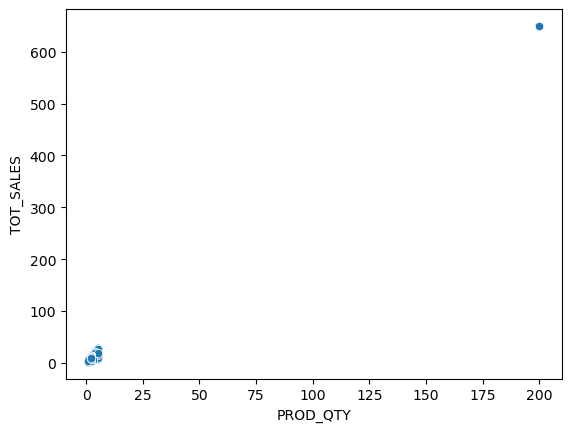

In [27]:
sns.scatterplot(data=merged,y='TOT_SALES',x='PROD_QTY');

In [28]:
merged[(merged['TOT_SALES']==650) | (merged['PROD_QTY']==200)]

,DATE,STORE_NBR,LYLTY_CARD_NBR,TXN_ID,PROD_NBR,PROD_NAME,PROD_QTY,TOT_SALES,PACK_SIZE,BRAND_NAME,LIFESTAGE,PREMIUM_CUSTOMER
65404,2018-08-19,226,226000,226201,4,Dorito Corn Chp Supreme 380g,200,650.0,380,Doritos,OLDER FAMILIES,Premium
65405,2019-05-20,226,226000,226210,4,Dorito Corn Chp Supreme 380g,200,650.0,380,Doritos,OLDER FAMILIES,Premium


In [29]:
merged = merged[merged['LYLTY_CARD_NBR']!=226000]

## 9. Dataset saving

In [30]:
merged.to_csv('cleaned_data.csv', index=False)

In [31]:
merged

,DATE,STORE_NBR,LYLTY_CARD_NBR,TXN_ID,PROD_NBR,PROD_NAME,PROD_QTY,TOT_SALES,PACK_SIZE,BRAND_NAME,LIFESTAGE,PREMIUM_CUSTOMER
0,2018-10-17,1,1000,1,5,Natural Chip Compny SeaSalt175g,2,6.0,175,Natural,YOUNG SINGLES/COUPLES,Premium
1,2019-05-14,1,1307,348,66,CCs Nacho Cheese 175g,3,6.3,175,CCs,MIDAGE SINGLES/COUPLES,Budget
2,2019-05-20,1,1343,383,61,Smiths Crinkle Cut Chips Chicken 170g,2,2.9,170,Smiths,MIDAGE SINGLES/COUPLES,Budget
3,2018-08-17,2,2373,974,69,Smiths Chip Thinly S/Cream&Onion 175g,5,15.0,175,Smiths,MIDAGE SINGLES/COUPLES,Budget
4,2018-08-18,2,2426,1038,108,Kettle Tortilla ChpsHny&Jlpno Chili 150g,3,13.8,150,Kettle,MIDAGE SINGLES/COUPLES,Budget
...,...,...,...,...,...,...,...,...,...,...,...,...
248226,2019-03-09,272,272319,270088,89,Kettle Sweet Chilli And Sour Cream 175g,2,10.8,175,Kettle,YOUNG SINGLES/COUPLES,Premium
248227,2018-08-13,272,272358,270154,74,Tostitos Splash Of Lime 175g,1,4.4,175,Tostitos,YOUNG SINGLES/COUPLES,Premium
248228,2018-11-06,272,272379,270187,51,Doritos Mexicana 170g,2,8.8,170,Doritos,YOUNG SINGLES/COUPLES,Premium
248229,2018-12-27,272,272379,270188,42,Doritos Corn Chip Mexican Jalapeno 150g,2,7.8,150,Doritos,YOUNG SINGLES/COUPLES,Premium
